In [1]:
import sqlite3
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv("processed_invoices.csv")
print(df.shape)
df.head()

(5543, 10)


,PONumber,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay
0,8106,10100,137483.78,2935.20,23,24,81,10100,137483.78,12.614130
1,8107,24,348.72,9.08,16,36,2,24,348.72,12.500000
2,8108,8466,60281.13,1549.81,22,30,165,8466,60281.13,12.632479
3,8109,2246,14298.09,408.72,23,30,23,2246,14298.09,12.626866
4,8110,8086,56493.23,1300.92,20,41,183,8086,56493.23,12.695271


In [83]:
# def create_invoice_risk_label(row):
    
#     if abs(row['invoice_dollars'] - row['total_item_dollars']) > 5:
#         return 1
        
#     if row['avg_receiving_delay'] > 10:
#         return 1

#     return 0

# df["flag_invoice"] = df.apply(create_invoice_risk_label, axis=1)


# print(df["flag_invoice"].value_counts())


flag_invoice
0    3693
1    1850
Name: count, dtype: int64


In [5]:
from sklearn.ensemble import IsolationForest

# Select features to look for anomalies
features = ['invoice_quantity', 'invoice_dollars', 'Freight', 'days_po_to_invoice', 'total_brands', 'avg_receiving_delay']

# Initialize Isolation Forest (contamination is the expected % of anomalies, e.g., 10%)
iso = IsolationForest(contamination=0.1, random_state=42)

# Fit and predict (-1 means anomaly/risk, 1 means normal)
preds = iso.fit_predict(df[features])

# Convert to 1 for risky/anomaly and 0 for normal
df["flag_invoice"] = [1 if x == -1 else 0 for x in preds]

print(df["flag_invoice"].value_counts())

flag_invoice
0    4988
1     555
Name: count, dtype: int64


<Axes: xlabel='flag_invoice'>

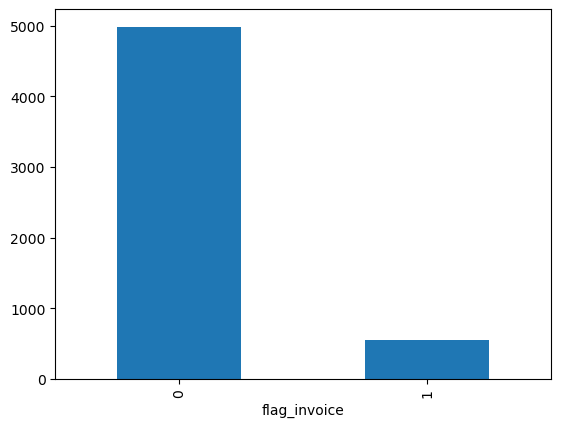

In [7]:
df['flag_invoice'].value_counts().plot(kind='bar')

In [9]:
df.corr()

,PONumber,invoice_quantity,invoice_dollars,Freight,days_po_to_invoice,days_to_pay,total_brands,total_item_quantity,total_item_dollars,avg_receiving_delay,flag_invoice
PONumber,1.000000,0.049230,0.058917,0.043617,-0.002234,0.012558,0.013423,0.049442,0.059221,-0.033794,0.041925
invoice_quantity,0.049230,1.000000,0.963831,0.946550,0.000526,0.022284,0.566394,0.706117,0.668171,-0.002750,0.770601
invoice_dollars,0.058917,0.963831,1.000000,0.985141,0.001610,0.025661,0.536952,0.667666,0.679537,0.002154,0.772119
Freight,0.043617,0.946550,0.985141,1.000000,0.003265,0.025513,0.536381,0.656616,0.670768,0.013077,0.772767
days_po_to_invoice,-0.002234,0.000526,0.001610,0.003265,1.000000,-0.370432,0.009519,0.005543,0.007931,0.520756,0.003153
days_to_pay,0.012558,0.022284,0.025661,0.025513,-0.370432,1.000000,0.020336,0.016203,0.015610,-0.025861,0.031274
total_brands,0.013423,0.566394,0.536952,0.536381,0.009519,0.020336,1.000000,0.783825,0.753092,0.000429,0.645675
total_item_quantity,0.049442,0.706117,0.667666,0.656616,0.005543,0.016203,0.783825,1.000000,0.963831,-0.008609,0.600616
total_item_dollars,0.059221,0.668171,0.679537,0.670768,0.007931,0.015610,0.753092,0.963831,1.000000,-0.009100,0.593206
avg_receiving_delay,-0.033794,-0.002750,0.002154,0.013077,0.520756,-0.025861,0.000429,-0.008609,-0.009100,1.000000,0.019719


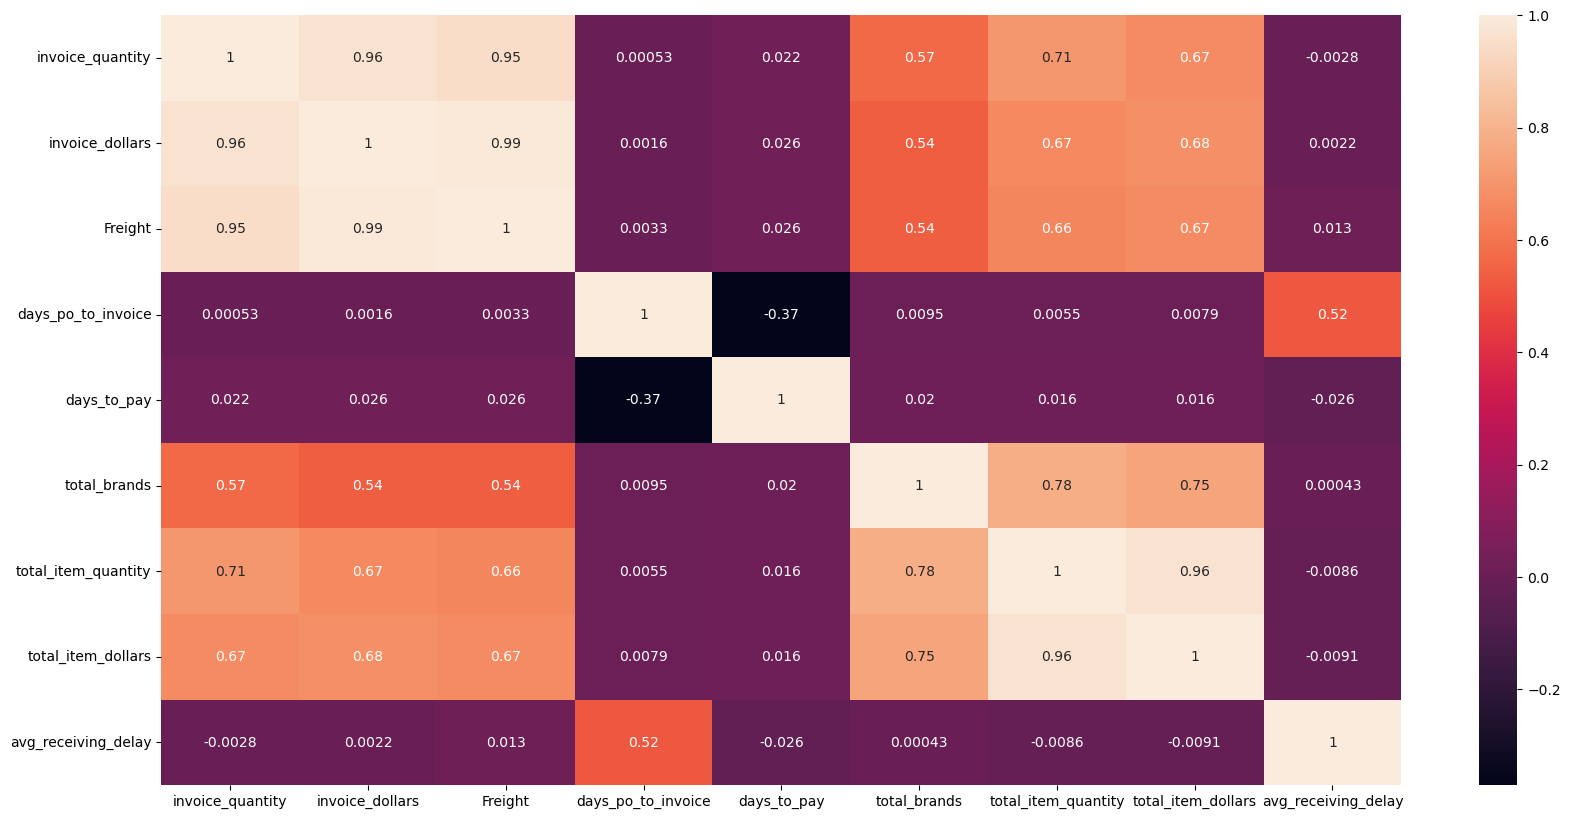

In [11]:
plt.figure(figsize=(20,10))
sns.heatmap(df.iloc[:,1:-1].corr(), annot=True)
plt.show()

In [13]:
flagged = df[df['flag_invoice']==1]
print(flagged)

      PONumber  invoice_quantity  invoice_dollars  Freight  \
0         8106             10100        137483.78  2935.20   
2         8108              8466         60281.13  1549.81   
4         8110              8086         56493.23  1300.92   
30        8142             11611        151890.49  3506.08   
45        8157              8061         68620.75  1591.50   
...        ...               ...              ...      ...   
5516     13635             15003        316863.94  1457.57   
5526     13645              9745         79904.22   375.55   
5527     13646             51177        386176.58  1737.79   
5533     13652               253          3844.39    20.38   
5539     13658             38896        502128.05  2761.70   

      days_po_to_invoice  days_to_pay  total_brands  total_item_quantity  \
0                     23           24            81                10100   
2                     22           30           165                 8466   
4                     20   

In [15]:
normal = df[df['flag_invoice']==0]
print(normal)

      PONumber  invoice_quantity  invoice_dollars  Freight  \
1         8107                24           348.72     9.08   
3         8109              2246         14298.09   408.72   
5         8111                24           185.40     9.50   
6         8112               427          5336.48   185.93   
7         8113               819          6139.47   196.61   
...        ...               ...              ...      ...   
5537     13656                83           626.72     3.01   
5538     13657                65          1248.61     5.74   
5540     13659               195          2599.66    11.70   
5541     13660                60           694.68     3.20   
5542     13661              4617         37300.48   186.50   

      days_po_to_invoice  days_to_pay  total_brands  total_item_quantity  \
1                     16           36             2                   24   
3                     23           30            23                 2246   
5                     21   

In [17]:
significant_features = []
non_significant_features = []
results = []

In [19]:
metrics = ['invoice_quantity', 'invoice_dollars', 'Freight', 'days_po_to_invoice',
          'days_to_pay','total_brands', 'total_item_quantity','total_item_dollars', 'avg_receiving_delay' ]

In [21]:
from scipy.stats import ttest_ind

for metric in metrics:
    flagged_mean = flagged[metric].mean()
    normal_mean = normal[metric].mean()

    t_stat, p_value = ttest_ind(
        flagged[metric].dropna(),
        normal[metric].dropna(),
        equal_var=False
    )

    if p_value < 0.05:
        significant_features.append(metric)
        results.append({
            "metric": metric,
            "flagged_mean": flagged_mean.round(2),
            "normal_mean": normal_mean.round(2),
            "p_value": p_value.round(3)
        })
    else:
        non_significant_features.append(metric)

In [23]:
from scipy.stats import ttest_ind

for metric in metrics:
    stat, p_val = ttest_ind(flagged[metric].dropna(), normal[metric].dropna(), equal_var=False)
    print(f"{metric}: p-value = {p_val:.5f}")

invoice_quantity: p-value = 0.00000
invoice_dollars: p-value = 0.00000
Freight: p-value = 0.00000
days_po_to_invoice: p-value = 0.82410
days_to_pay: p-value = 0.02427
total_brands: p-value = 0.00000
total_item_quantity: p-value = 0.00000
total_item_dollars: p-value = 0.00000
avg_receiving_delay: p-value = 0.14301


In [25]:
non_significant_features

['days_po_to_invoice', 'avg_receiving_delay']

In [27]:
significant_features

['invoice_quantity',
 'invoice_dollars',
 'Freight',
 'days_to_pay',
 'total_brands',
 'total_item_quantity',
 'total_item_dollars']

In [29]:
df.to_csv('../processed_invoices.csv', index=False)
print("Saved processed_invoices.csv successfully!")

Saved processed_invoices.csv successfully!
